[Original Study Here](https://pmc.ncbi.nlm.nih.gov/articles/PMC9518652/)

Start by importing the datasets and methods used. This is a replication study of our parent paper. We recreated the data cleanup, EDA, preprocessing, and two feature models. All of the code is referenced from the paper and outlined by ChatGPT. 

The primary goal of this model is to predict the amount of cases in 2021 given the amount of cases in 2020. This involves columns life expectancy, expected schooling, mean schooling, GNI per capita, COVID cases per million in 2020, and COVID cases per million in 2021. 

This dataset is a combination of two datasets, OWID and HDI in 2020. This has been recreated later with archives of datasets, which accounts for the discrepancies between the data. The datasets were combined and preprocessed in R. 

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor

from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, cross_validate

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    max_error,
    make_scorer
)

In [38]:
df = pd.read_csv("data/train_set.csv")

columns = [
    "LIFE_EXP",
    "EXP_SCHOOLING",
    "MEAN_SCHOOLING",
    "GNI",
    "CASES_2020",
    "CASES_2021"
]

print(df[columns].describe())

         LIFE_EXP  EXP_SCHOOLING  MEAN_SCHOOLING           GNI     CASES_2020  \
count  128.000000     128.000000      128.000000    128.000000     128.000000   
mean    72.168028      13.573762        9.030782  21092.601562   16424.794775   
std      6.925981       2.946644        3.150286  19944.281206   19949.869712   
min     53.082000       7.037250        1.341352    866.192870       0.257592   
25%     66.922750      11.444241        6.740017   5988.143120     804.222575   
50%     72.512000      13.503225        9.565000  13818.305000    7983.601850   
75%     77.203500      15.845591       11.395000  31240.128623   29530.878500   
max     83.675000      20.939440       14.260000  89601.730150  100135.470000   

          CASES_2021  
count     128.000000  
mean    66628.690787  
std     65507.004454  
min         9.290658  
25%      4683.305950  
50%     53565.620000  
75%    106039.265000  
max    286282.340000  


These numbers are close to Table 3. in the original paper. 
Distibution Plots

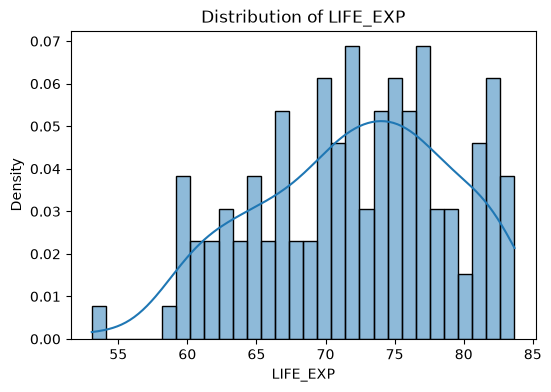

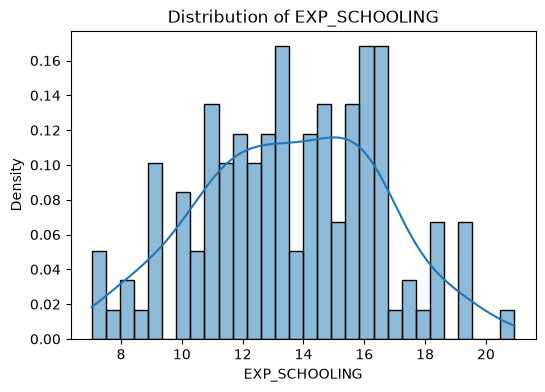

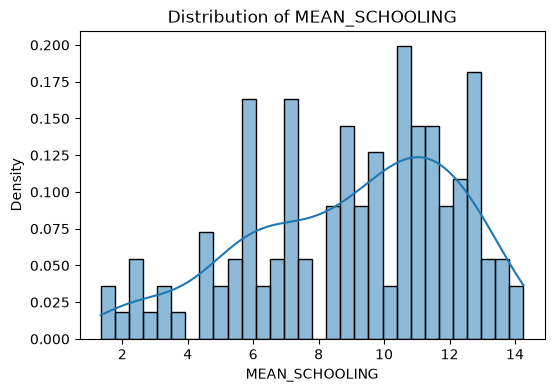

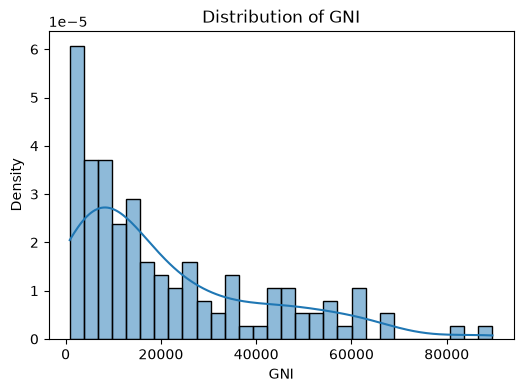

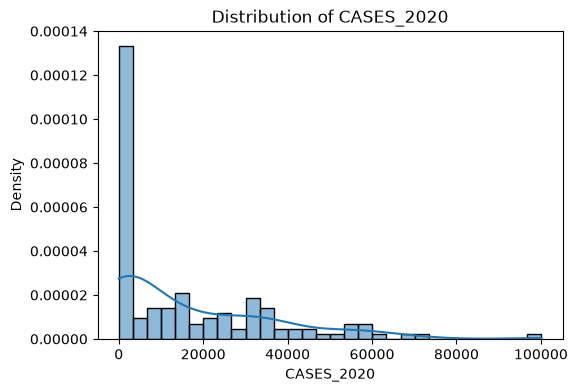

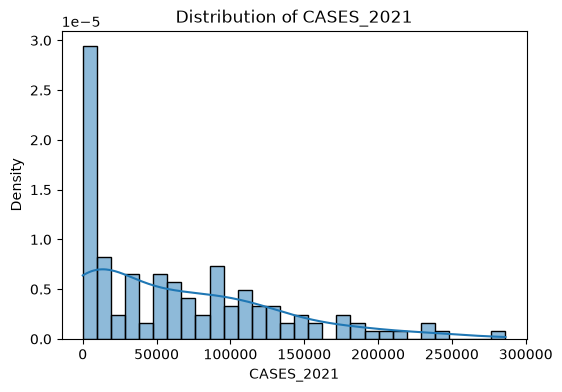

In [39]:
for col in columns:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        df[col],
        bins=30,
        kde=True,
        stat="density"
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Density")

    plt.show()

                LIFE_EXP  EXP_SCHOOLING  MEAN_SCHOOLING    GNI  CASES_2020  \
LIFE_EXP           1.000          0.733           0.756  0.762       0.577   
EXP_SCHOOLING      0.733          1.000           0.765  0.650       0.414   
MEAN_SCHOOLING     0.756          0.765           1.000  0.687       0.525   
GNI                0.762          0.650           0.687  1.000       0.598   
CASES_2020         0.577          0.414           0.525  0.598       1.000   
CASES_2021         0.619          0.546           0.595  0.575       0.855   

                CASES_2021  
LIFE_EXP             0.619  
EXP_SCHOOLING        0.546  
MEAN_SCHOOLING       0.595  
GNI                  0.575  
CASES_2020           0.855  
CASES_2021           1.000  


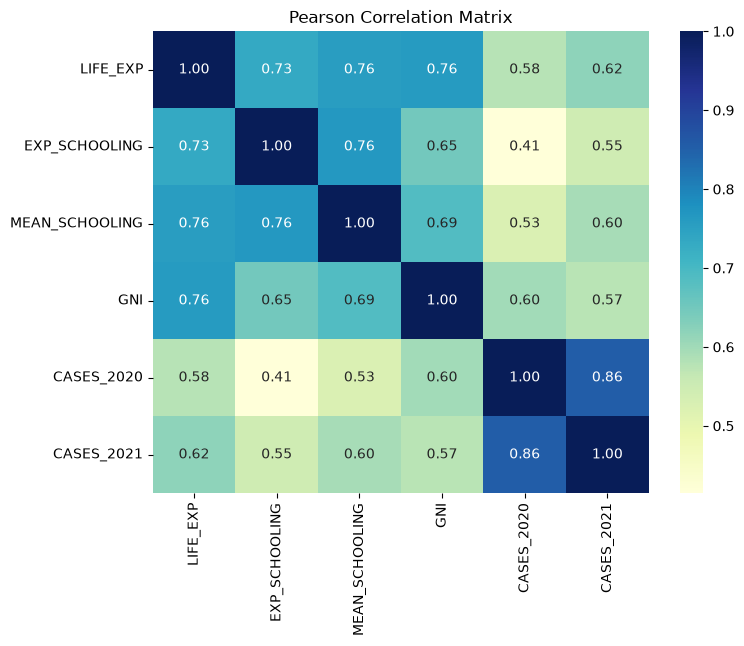

In [40]:
corr = df[columns].corr(method="pearson")

print(corr.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Pearson Correlation Matrix")
plt.show()

Now that we've recreated the data distribution to align with the paper's original code, we can proceed with recreating the models. 

Although the method is not explicitly stated, the charts imply the original paper scaled all of attributes from 0-1. We will recreate this scaling with sklearn.

In [41]:
scaler = MinMaxScaler()

scaled_values = scaler.fit_transform(
    df[columns]
)

df_scaled = pd.DataFrame(
    scaled_values,
    columns=columns,
    index=df.index
)

print(df_scaled.describe())

         LIFE_EXP  EXP_SCHOOLING  MEAN_SCHOOLING         GNI  CASES_2020  \
count  128.000000     128.000000      128.000000  128.000000  128.000000   
mean     0.623869       0.470179        0.595219    0.227940    0.164024   
std      0.226391       0.211955        0.243856    0.224761    0.199229   
min      0.000000       0.000000        0.000000    0.000000    0.000000   
25%      0.452416       0.317000        0.417897    0.057722    0.008029   
50%      0.635113       0.465105        0.636572    0.145963    0.079726   
75%      0.788465       0.633594        0.778228    0.342297    0.294907   
max      1.000000       1.000000        1.000000    1.000000    1.000000   

       CASES_2021  
count  128.000000  
mean     0.232713  
std      0.228827  
min      0.000000  
25%      0.016327  
50%      0.187081  
75%      0.370381  
max      1.000000  


Next, we will define the feature models to predict the amount of cases in 2021. The first feature model only uses the CASES_2020 column, whereas the second model uses all five columns to predict CASES_2021. Each of these features were put through linear regression, random forest, and AdaBoost models for prediction. We will proceed with recreating all six models.

In [42]:
y = df_scaled["CASES_2021"]

#feature model 1
X1 = df_scaled[["CASES_2020"]
]

#feature model 2
X2 = df_scaled[
    ["CASES_2020",
        "LIFE_EXP",
        "EXP_SCHOOLING",
        "MEAN_SCHOOLING",
        "GNI"
    ]
]

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=1
    ),
    "AdaBoost": AdaBoostRegressor(
        n_estimators=50,
        random_state=0
    )
}

In [43]:
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=1
)

def evaluate_model(model, X, y, cv):
    scoring = {
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "max_error": make_scorer(
            max_error,
            greater_is_better=False
        )
    }

    cv_results = cross_validate(model, X, y, cv=cv,scoring=scoring)
    r2_scores = cv_results["test_r2"]
    mean_r2 = np.mean(r2_scores)

#error metrics using scikit, * -1

    mae_scores = -cv_results["test_mae"]
    mse_scores = -cv_results["test_mse"]
    max_error_scores = -cv_results["test_max_error"]

    mean_mae = np.mean(mae_scores)
    mean_mse = np.mean(mse_scores)

#rmse averaged across each fold
    rmse_scores = np.sqrt(mse_scores)
    mean_rmse = np.mean(rmse_scores)

    mean_max_error = np.mean(max_error_scores)

    predictions = cross_val_predict(
        model, X, y, cv=cv )


    results = {
        "R2": mean_r2,
        "MAE": mean_mae,
        "MSE": mean_mse,
        "RMSE": mean_rmse,
        "Max Error": mean_max_error
    }

    return results, r2_scores, predictions

In [44]:
#model one

results_model1 = {}
fold_scores_model1 = {}
predictions_model1 = {}

for name, model in models.items():
    results, fold_scores, predictions = evaluate_model(model, X1, y, cv)

    results_model1[name] = results
    fold_scores_model1[name] = fold_scores
    predictions_model1[name] = predictions


results_df1 = pd.DataFrame(results_model1).T

In [45]:
#model two

results_model2 = {}
fold_scores_model2 = {}
predictions_model2 = {}

for name, model in models.items():
    results, fold_scores, predictions = evaluate_model(model, X2, y, cv)
    results_model2[name] = results
    fold_scores_model2[name] = fold_scores
    predictions_model2[name] = predictions


results_df2 = pd.DataFrame(results_model2).T

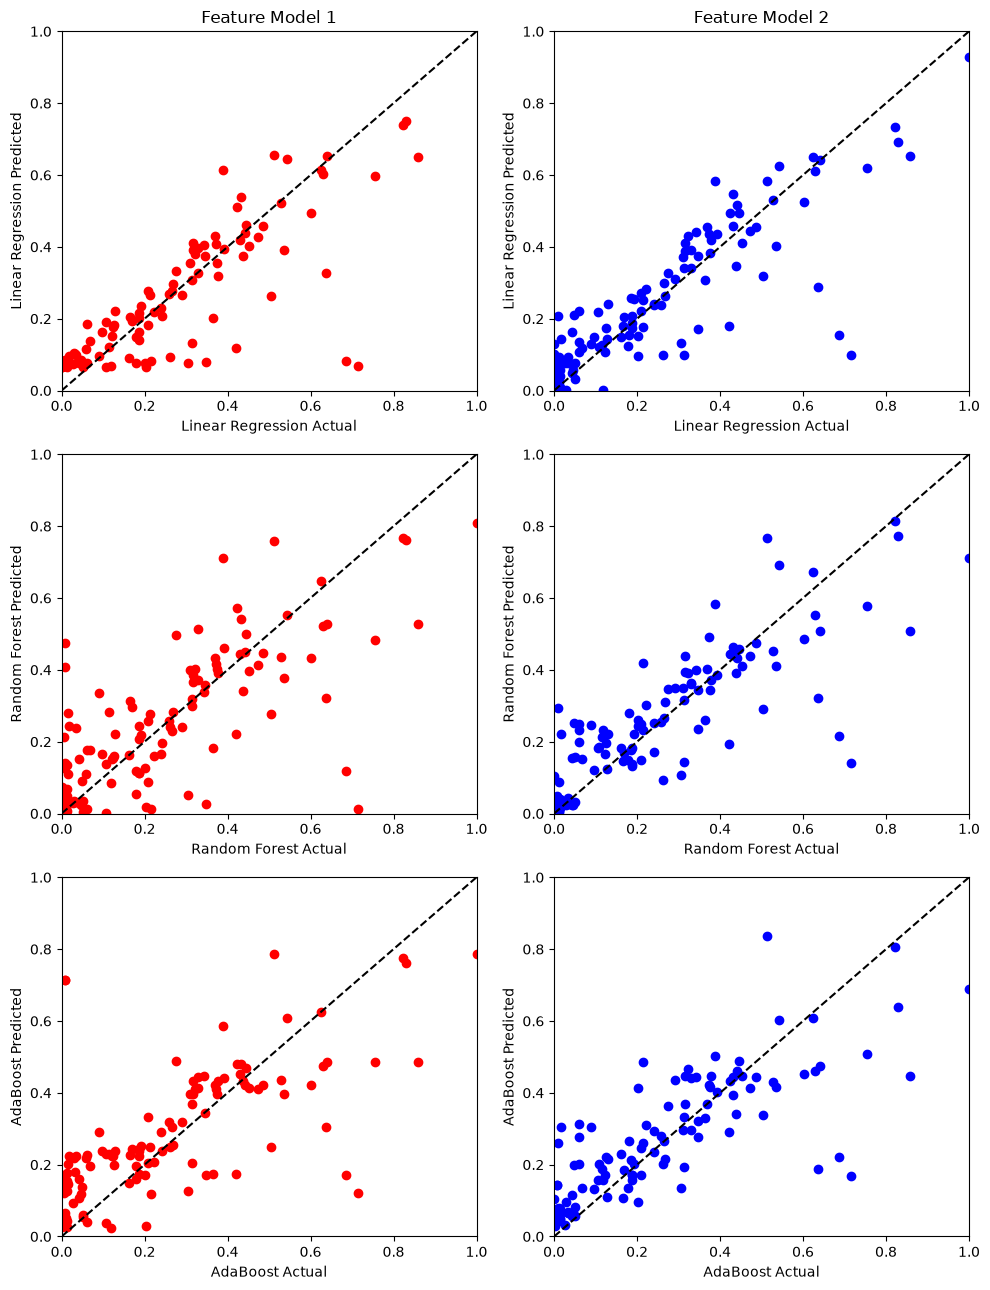

In [48]:
fig, axes = plt.subplots(3, 2, figsize=(10, 13))

#row 1: linear reg
#model 1
axes[0, 0].scatter(
    y,
    predictions_model1["Linear Regression"],
    color="red"
)

axes[0, 0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black"
)

axes[0, 0].set_title("Feature Model 1")
axes[0, 0].set_xlabel("Linear Regression Actual")
axes[0, 0].set_ylabel("Linear Regression Predicted")
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_ylim(0, 1)


#model 2
axes[0, 1].scatter(
    y,
    predictions_model2["Linear Regression"],
    color="blue"
)

axes[0, 1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black"
)

axes[0, 1].set_title("Feature Model 2")
axes[0, 1].set_xlabel("Linear Regression Actual")
axes[0, 1].set_ylabel("Linear Regression Predicted")
axes[0, 1].set_xlim(0, 1)
axes[0, 1].set_ylim(0, 1)


#row 2: random forest
#model 1
axes[1, 0].scatter(
    y,
    predictions_model1["Random Forest"],
    color="red"
)

axes[1, 0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black"
)

axes[1, 0].set_xlabel("Random Forest Actual")
axes[1, 0].set_ylabel("Random Forest Predicted")
axes[1, 0].set_xlim(0, 1)
axes[1, 0].set_ylim(0, 1)


#model 2
axes[1, 1].scatter(
    y,
    predictions_model2["Random Forest"],
    color="blue"
)

axes[1, 1].plot(
    [0, 1],
    [0, 1],
    linestyle="--", 
    color="black"
)

axes[1, 1].set_xlabel("Random Forest Actual")
axes[1, 1].set_ylabel("Random Forest Predicted")
axes[1, 1].set_xlim(0, 1)
axes[1, 1].set_ylim(0, 1)


#row 3: adaboost
#model 1
axes[2, 0].scatter(
    y,
    predictions_model1["AdaBoost"],
    color="red"
)

axes[2, 0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black"
)

axes[2, 0].set_xlabel("AdaBoost Actual")
axes[2, 0].set_ylabel("AdaBoost Predicted")
axes[2, 0].set_xlim(0, 1)
axes[2, 0].set_ylim(0, 1)


#model 2
axes[2, 1].scatter(
    y,
    predictions_model2["AdaBoost"],
    color="blue"
)

axes[2, 1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black"
)

axes[2, 1].set_xlabel("AdaBoost Actual")
axes[2, 1].set_ylabel("AdaBoost Predicted")
axes[2, 1].set_xlim(0, 1)
axes[2, 1].set_ylim(0, 1)


plt.tight_layout()
plt.show()